# Comparaison de méthodes de comptage de mots

Ce notebook a pour but de comparer trois approches pour le comptage du nombre d'occurrences de mots dans un texte :
1. Une version Python séquentielle simple.
2. Une version pseudo-MapReduce en Python (reproduisant les étapes map, shuffle et reduce).
3. Une version distribuée avec Hadoop MapReduce.

In [1]:
import os
import time
import random
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
import subprocess

def generer_fichier_mots(nom_fichier, distribution_mots, m):
    """
    Génère un fichier de mots à partir d'une distribution de base.
    distribution_mots : dictionnaire {mot: occurences_souhaitees_dans_le_bloc}
    m : nombre de fois que ce bloc de base est dupliqué.
    """
    # 1. Création du bloc de base de N lignes
    mots_de_base = []
    for mot, frequence in distribution_mots.items():
        mots_de_base.extend([f"{mot}\n"] * frequence)
    
    # 2. Mélange pour que les mots soient à différentes positions
    random.shuffle(mots_de_base)
    
    N = len(mots_de_base)
    
    # 3. Écriture du fichier en dupliquant le bloc m fois
    with open(nom_fichier, 'w', encoding='utf-8') as f:
        for _ in range(m):
            f.writelines(mots_de_base)
    
    taille_ko = os.path.getsize(nom_fichier) / 1024
    print(f"Fichier {nom_fichier} généré : {N * m} lignes, Taille: {taille_ko:.2f} Ko")

In [11]:
# --- Méthode 1 : Python Simple ---
def wordcount_simple(fichier):
    with open(fichier, 'r', encoding='utf-8') as f:
        mots = f.read().split()
    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

# --- Méthode 2 : Pseudo-MapReduce Python ---
def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

def wordcount_pseudo_mapreduce(fichier):
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))
            
    grouped = shuffle(mapped)
    return reducer(grouped)

# --- Méthode 3 : Hadoop MapReduce (Wrapper) ---
def wordcount_hadoop(fichier_local, hdfs_input_dir, hdfs_output_dir):
    try:
        # On définit le dossier racine de Hadoop il faut remplacer 'urmenus' par votre nom d'utilisateur
        # On défini les chemin absolut car mon environnement conda conflicte avec les commande de hadoop
        hadoop_home = os.environ.get("HADOOP_HOME", "/home/urmenus/hadoop")
        
        # On définit les chemins absolus vers les exécutables
        hdfs_bin = f"{hadoop_home}/bin/hdfs"
        hadoop_bin = f"{hadoop_home}/bin/hadoop"
        jar_path = f"{hadoop_home}/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.0.jar"
        
        # 1. Nettoyage et préparation HDFS
        # On supprime l'ancien dossier d'entrée pour éviter l'accumulation des datasets
        subprocess.run([hdfs_bin, "dfs", "-rm", "-r", "-f", hdfs_input_dir], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        subprocess.run([hdfs_bin, "dfs", "-rm", "-r", "-f", hdfs_output_dir], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        
        subprocess.run([hdfs_bin, "dfs", "-mkdir", "-p", hdfs_input_dir], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        subprocess.run([hdfs_bin, "dfs", "-put", "-f", fichier_local, hdfs_input_dir], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        
        # 2. Lancement du job MapReduce
        cmd = [hadoop_bin, "jar", jar_path, "wordcount", hdfs_input_dir, hdfs_output_dir]
        subprocess.run(cmd, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=True)

        # 3. Récupération et lecture du résultat depuis HDFS
        cat_cmd = [hdfs_bin, "dfs", "-cat", f"{hdfs_output_dir}/part-r-00000"]
        output_texte = subprocess.check_output(cat_cmd, text=True, stderr=subprocess.DEVNULL)

        # 4. Transformation du texte en dictionnaire Python
        resultat_dictionnaire = {}
        for ligne in output_texte.strip().split('\n'):
            if ligne:
                # Les résultats Hadoop sont séparés par une tabulation
                mot, compte = ligne.split()
                resultat_dictionnaire[mot] = int(compte)
                
        return resultat_dictionnaire
    
    except subprocess.CalledProcessError as e:
        print("Erreur d'exécution de la commande Hadoop:", e)
        return {}
    except FileNotFoundError as e:
        print(f"Fichier introuvable (vérifiez les chemins) : {e}")
        return {}
    except Exception as e:
        print("Erreur inattendue:", e)
        return {}

In [12]:
# Définition du bloc de base avec des mots et leurs occurrences (ex: N = 100 au total)
distribution_base = {
    "chat": 15,
    "chien": 20,
    "voiture": 7,
    "arbre": 18,
    "maison": 10,
    "ordinateur": 12,
    "python": 18
}

# Valeurs de m pour générer des fichiers de plus en plus gros
multiplicateurs = [10, 100, 1000, 5000, 10000] 

resultats = []
simple_res = {}
pseudo_res = {}
hadoop_res = {}

# Exécution des tests
for m in multiplicateurs:
    fichier_test = f"dataset_{m}.txt"
    generer_fichier_mots(fichier_test, distribution_base, m)
    
    # Calcul du nombre total de lignes (N * m)
    N_total = sum(distribution_base.values()) * m
    
    # Test Python Simple
    start = time.time()
    simple_res = wordcount_simple(fichier_test)
    temps_simple = time.time() - start

    # Test Pseudo-MapReduce
    start = time.time()
    pseudo_res = wordcount_pseudo_mapreduce(fichier_test)
    temps_pseudo = time.time() - start
    
    # Test Hadoop MapReduce
    start = time.time()
    hadoop_res = wordcount_hadoop(fichier_test, "/user/etudiant/input", f"/user/etudiant/output_{m}")
    temps_hadoop = time.time() - start

    # Sauvegarde des résultats pour le tableau
    resultats.append({
        "Multiplicateur (m)": m,
        "Total de lignes": N_total,
        "Python Simple (s)": temps_simple,
        "Pseudo-MapReduce (s)": temps_pseudo,
        "Hadoop MapReduce (s)": temps_hadoop
    })

# Affichage des résultats des algorithmes
print('-' * 10)
print(f"Approche python simple, de {m} duplication :")
print(simple_res)
print('-' * 10)

print('-' * 10)
print(f"Approche pseudo map reduce {m} duplication :")
print(pseudo_res)
print('-' * 10)

print('-' * 10)
print(f"Approche hadoop {m} duplication :")
print(hadoop_res)
print('-' * 10)

# Création et affichage du tableau comparatif avec Pandas
df_resultats = pd.DataFrame(resultats)
print("\nTableau Comparatif des Temps d'Exécution")
display(df_resultats)

Fichier dataset_10.txt généré : 1000 lignes, Taille: 6.71 Ko
Fichier dataset_100.txt généré : 10000 lignes, Taille: 67.09 Ko
Fichier dataset_1000.txt généré : 100000 lignes, Taille: 670.90 Ko
Fichier dataset_5000.txt généré : 500000 lignes, Taille: 3354.49 Ko
Fichier dataset_10000.txt généré : 1000000 lignes, Taille: 6708.98 Ko
----------
Approche python simple, de 10000 duplication :
{'chien': 200000, 'arbre': 180000, 'maison': 100000, 'python': 180000, 'chat': 150000, 'ordinateur': 120000, 'voiture': 70000}
----------
----------
Approche pseudo map reduce 10000 duplication :
{'chien': 200000, 'arbre': 180000, 'maison': 100000, 'python': 180000, 'chat': 150000, 'ordinateur': 120000, 'voiture': 70000}
----------
----------
Approche hadoop 10000 duplication :
{'arbre': 180000, 'chat': 150000, 'chien': 200000, 'maison': 100000, 'ordinateur': 120000, 'python': 180000, 'voiture': 70000}
----------

Tableau Comparatif des Temps d'Exécution


,Multiplicateur (m),Total de lignes,Python Simple (s),Pseudo-MapReduce (s),Hadoop MapReduce (s)
0,10,1000,0.000243,0.000500,8.580933
1,100,10000,0.001384,0.004418,8.444823
2,1000,100000,0.010040,0.038157,8.483297
3,5000,500000,0.058108,0.210717,8.599681
4,10000,1000000,0.142210,0.463448,9.572958


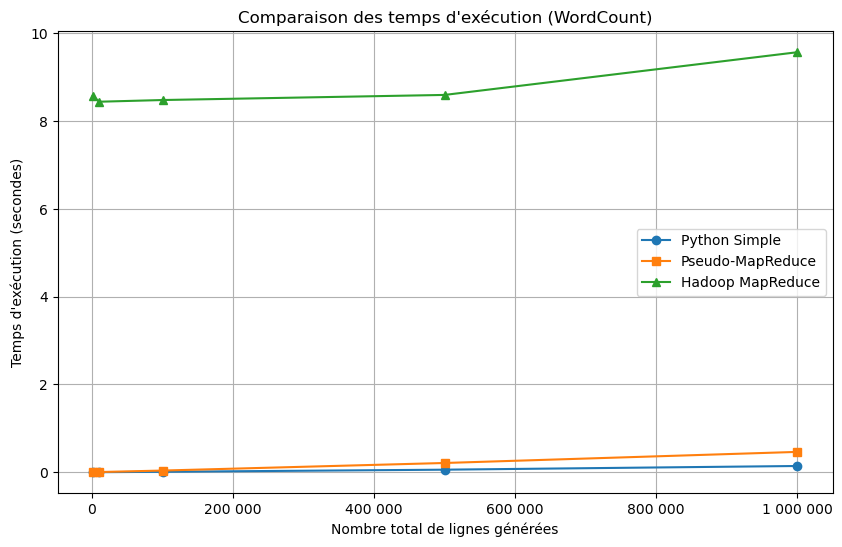

In [14]:
import matplotlib.ticker as ticker

# Tracé du graphique à partir du DataFrame
plt.figure(figsize=(10, 6))

plt.plot(df_resultats["Total de lignes"], df_resultats["Python Simple (s)"], marker='o', label='Python Simple')
plt.plot(df_resultats["Total de lignes"], df_resultats["Pseudo-MapReduce (s)"], marker='s', label='Pseudo-MapReduce')
plt.plot(df_resultats["Total de lignes"], df_resultats["Hadoop MapReduce (s)"], marker='^', label='Hadoop MapReduce')

plt.title("Comparaison des temps d'exécution (WordCount)")
plt.xlabel("Nombre total de lignes générées")
plt.ylabel("Temps d'exécution (secondes)")

# Désactiver la notation scientifique
plt.ticklabel_format(style='plain', axis='x')
# Formater les nombres avec un espace pour les milliers
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',').replace(',', ' ')))

plt.legend()
plt.grid(True)
plt.show()

### Conclusion

On remarque que les trois approche renvoient les mêmes résultats attendus, ce qui valide notre logique de base, et que notre déploiement distribué avec hadoop a foncionné.

On remarque que pour des fichiers allant jusqu'à 1 million de lignes, les méthodes locales sont extrémement rapide, 0.142210s  pour le python simple	et 0.463448s pour la méthode pseudo map reduce, tandis que l'approche distribuée	met 9.572958s. cet écart s'explique par la latence due au démarrage, l'orchestration par YARN, création des conteneur lancement de VM Java, le transfert HDFS.

Bien que hadoop semble lent sur ces jeux de test, la courbe de temps de l'approche python simple, avec l'augmentation de la taille du fichier fini par croiser celle de hadoop sur de volumess massifs. C'est à ce momment de bascule qu'une machine saturée le modèle distribué mapreduce s'avère performent grace à la puissance de paralélisation
